In [18]:
import duckdb
import matplotlib.pyplot as plt

con = duckdb.connect("../data/projet.duckdb", read_only=True)
con.execute("SET TimeZone = 'UTC'")
df = con.execute("SELECT * FROM donnees").df()
df.head()





            


                    

,debut_utc,demande_mw,interpolee,temp_ponderee,temp_montreal,temp_quebec,temp_sherbrooke,humidite_montreal,vent_montreal
0,2019-01-01 05:00:00+00:00,23762.55,False,1.043378,1.9,-3.0,-0.2,94.0,26.0
1,2019-01-01 06:00:00+00:00,23830.23,False,0.923006,1.7,-2.8,0.0,92.0,28.0
2,2019-01-01 07:00:00+00:00,23608.07,False,1.104411,1.9,-2.8,0.5,94.0,17.0
3,2019-01-01 08:00:00+00:00,23562.48,False,1.473084,2.3,-2.6,0.9,94.0,22.0
4,2019-01-01 09:00:00+00:00,23546.16,False,1.231494,2.0,-2.5,0.5,95.0,18.0


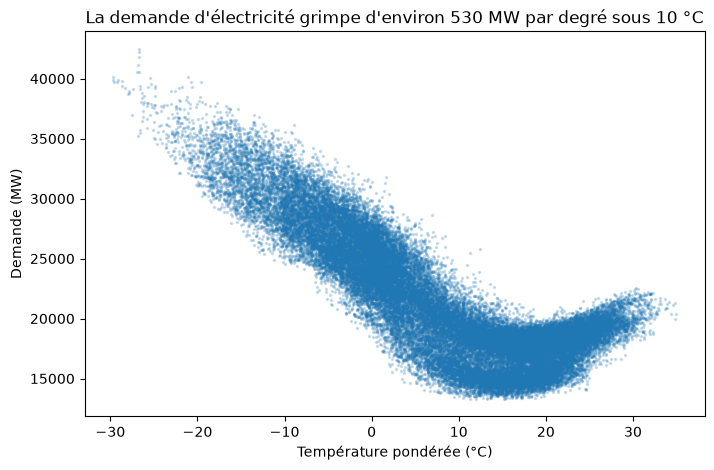

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["temp_ponderee"], df["demande_mw"], s=2, alpha=0.2)
ax.set_xlabel("Température pondérée (°C)")
ax.set_ylabel("Demande (MW)")
ax.set_title("La demande d'électricité grimpe d'environ 530 MW par degré sous 10 °C")
plt.show()

In [20]:
df["locale"] = df["debut_utc"].dt.tz_convert("America/Toronto")
df["heure"] = df["locale"].dt.hour
df["jour_semaine"] = df["locale"].dt.dayofweek  # 0 = lundi, 6 = dimanche
df["fin_de_semaine"] = df["jour_semaine"] >= 5
df["mois"] = df["locale"].dt.month
df["annee"] = df["locale"].dt.year
df["saison"] = df["mois"].map({12: "hiver", 1: "hiver", 2: "hiver",
                               6: "été", 7: "été", 8: "été"}).fillna("mi-saison")

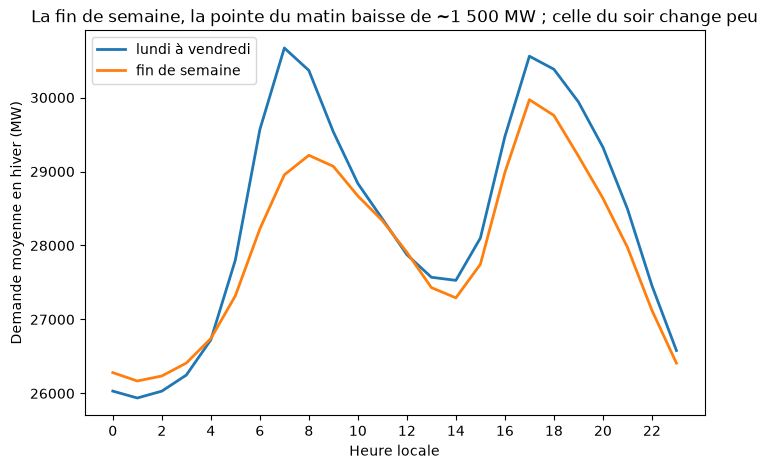

In [21]:
hiver = df[df["saison"] == "hiver"]
comparaison = hiver.groupby(["fin_de_semaine", "heure"])["demande_mw"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(comparaison.index, comparaison[False], label="lundi à vendredi", linewidth=2)
ax.plot(comparaison.index, comparaison[True], label="fin de semaine", linewidth=2)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Heure locale")
ax.set_ylabel("Demande moyenne en hiver (MW)")
ax.set_title("La fin de semaine, la pointe du matin baisse de ~1 500 MW ; celle du soir change peu")
ax.legend()
plt.show()

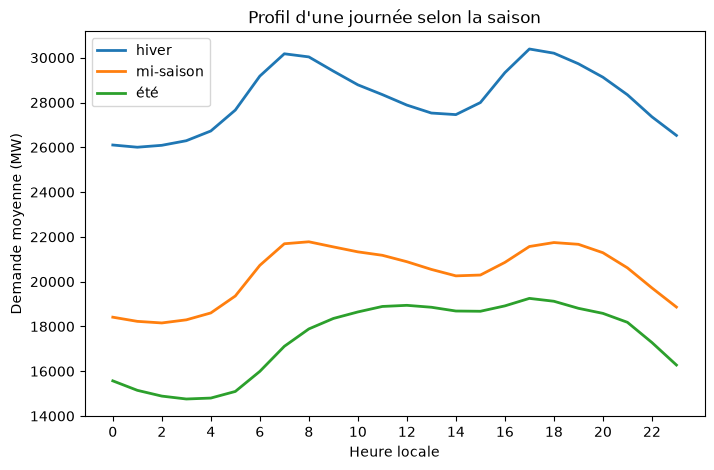

In [22]:
profil = df.groupby(["saison", "heure"])["demande_mw"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(8, 5))
for saison in ["hiver", "mi-saison", "été"]:
    ax.plot(profil.index, profil[saison], label=saison, linewidth=2)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Heure locale")
ax.set_ylabel("Demande moyenne (MW)")
ax.set_title("Profil d'une journée selon la saison")
plt.legend()
plt.show()

       annee                    locale  demande_mw  temp_ponderee
511     2019 2019-01-22 07:00:00-05:00    37865.76     -23.041126
9991    2020 2020-02-21 07:00:00-05:00    36107.36     -19.699340
18295   2021 2021-02-01 07:00:00-05:00    36399.57     -17.531094
26935   2022 2022-01-27 07:00:00-05:00    40178.57     -21.101045
35873   2023 2023-02-03 17:00:00-05:00    42472.83     -26.653154


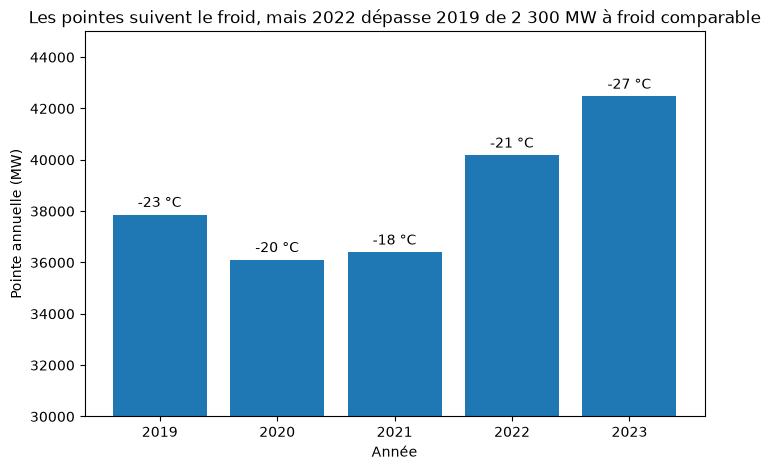

In [24]:
# La pointe de chaque hiver et la température à ce moment-là
idx = df.groupby("annee")["demande_mw"].idxmax()
pointes = df.loc[idx, ["annee", "locale", "demande_mw", "temp_ponderee"]]
print(pointes)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(pointes["annee"].astype(str), pointes["demande_mw"])
for x, (mw, t) in enumerate(zip(pointes["demande_mw"], pointes["temp_ponderee"])):
    ax.text(x, mw + 300, f"{t:.0f} °C", ha="center")
ax.set_ylim(30000, 45000)
ax.set_xlabel("Année")
ax.set_ylabel("Pointe annuelle (MW)")
ax.set_title("Les pointes suivent le froid, mais 2022 dépasse 2019 de 2 300 MW à froid comparable")
plt.show()